# 2. Validation: finite elements vs Monte Carlo

**Notebook 2 of 3** · [1. Theory](01_theory.ipynb) · [3. A real-world application](03_application.ipynb)

---

Notebook 1 proved that the solution of a Dirichlet–Poisson problem is an expectation over diffusion paths. Here we **test it numerically** on the problem solved in `fem/BVPUSC.edp`:

$$
\Delta u+b\cdot\nabla u=-g\ \ \text{in } D=(-1,1)^2,\qquad u=0\ \text{ on }\partial D,
\qquad b=(1,2),\quad g(x,y)=2\pi^2\sin(\pi x)\sin(\pi y).
$$

That is $\mathcal{L}=b\cdot\nabla+\Delta$, so $a=I$ and the associated diffusion is $dX_t=b\,dt+\sqrt2\,dW_t$.

We will:

1. Load the **finite-element** solution computed by FreeFEM++ (our reference).
2. Compute the **Monte Carlo** solution and compare. A naive implementation gives a large, systematic discrepancy. We diagnose it.
3. Use a problem with a **known exact solution** to measure the error of each method separately.
4. Measure how the Monte Carlo **bias** decays with the time step, with and without the boundary correction.

> **Reproducing the FEM data.** `fem/fem_solution.txt` and `fem/fem_solution_field.txt` are produced by FreeFEM++:
> `cd fem && FreeFem++ BVPUSC.edp`. They are included in the repository so this notebook runs without FreeFEM.

## 1. The finite-element reference

The weak form implemented in `BVPUSC.edp` (multiply by $v\in H^1_0$, integrate by parts; the boundary term vanishes because $v=0$ on $\partial D$) is

$$
\int_D\nabla u\cdot\nabla v\,dx-\int_D(b\cdot\nabla u)\,v\,dx=\int_D g\,v\,dx\qquad\forall v\in H^1_0(D),
$$

discretised with $P_1$ elements on a $60\times60$ structured mesh. `fem/fem_solution.txt` contains $u_h$ on a $7\times7$ grid of interior points; `fem/fem_solution_field.txt` contains the full nodal field.

To make the notebook self-contained we also include a minimal $P_1$ solver in Python (`src/fem2d.py`) that uses the **same weak form** (and handles a general matrix $a$, which notebook 3 needs). We first check that it reproduces the FreeFEM++ output.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from src import plotstyle
from src.feynman_kac import feynman_kac_solver, Box
from src.fem2d import solve_dirichlet_poisson

plotstyle.apply()

# --- Problem data (identical to fem/BVPUSC.edp) -------------------------------------
a = np.eye(2)                       # a = sigma sigma^T / 2  ->  Laplacian
b = np.array([1.0, 2.0])            # constant drift
g   = lambda X: 2 * np.pi**2 * np.sin(np.pi * X[:, 0]) * np.sin(np.pi * X[:, 1])
phi = lambda X: np.zeros(len(X))    # homogeneous Dirichlet condition
D = Box([-1.0, -1.0], [1.0, 1.0])

# --- FreeFEM++ output -----------------------------------------------------------------
fem = np.loadtxt("fem/fem_solution.txt")            # columns: x, y, u_h(x, y) on a 7x7 grid
pts, u_fem = fem[:, :2], fem[:, 2]
field = np.loadtxt("fem/fem_solution_field.txt")    # all mesh nodes

# --- Cross-check: our Python P1 solver on the same 60x60 mesh --------------------------
sol60 = solve_dirichlet_poisson(a, b, g, phi, [-1, -1], [1, 1], nx=60)
print("max |u_Python - u_FreeFEM| over the 49 grid points:", f"{np.abs(sol60(pts) - u_fem).max():.1e}")

max |u_Python - u_FreeFEM| over the 49 grid points: 6.2e-07

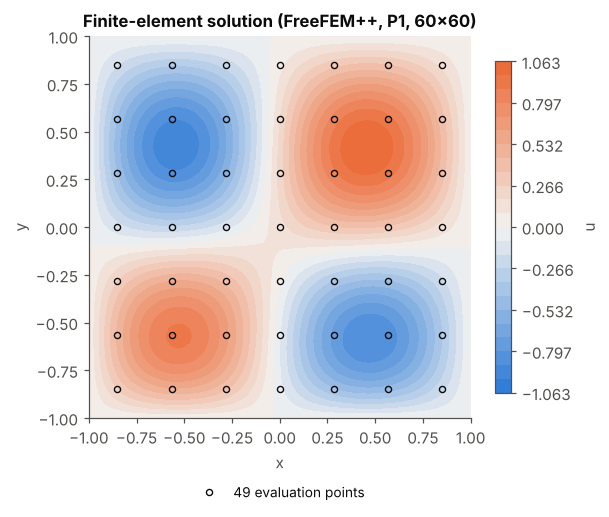

In [2]:
fig, ax = plt.subplots(figsize=(5.6, 4.6))
m = np.abs(field[:, 2]).max()
cs = ax.tricontourf(field[:, 0], field[:, 1], field[:, 2], levels=np.linspace(-m, m, 25), cmap=plotstyle.DIVERGING)
ax.plot(pts[:, 0], pts[:, 1], "o", mfc="none", mec=plotstyle.INK, ms=4, mew=0.9, label="49 evaluation points")
ax.set(title="Finite-element solution (FreeFEM++, P1, 60×60)", xlabel="x", ylabel="y", aspect="equal")
ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14))
fig.colorbar(cs, ax=ax, shrink=0.85, label="u")
fig.savefig("figures/fem_solution.png")
plt.show()

## 2. Monte Carlo at the 49 points: a systematic discrepancy

We estimate $u$ at the same 49 points with $N$ paths each and compare it to the FEM value. Because the FEM mesh is fine ($O(h^2)$ error, quantified in Section 3) we treat it as the reference here.

A quantity that tells *statistical noise* from *systematic error* is the **z-score** $z=(u_{MC}-u_{FEM})/\mathrm{se}$, with se the Monte Carlo standard error. If the only error were statistical, $z$ would behave like a standard normal: about 0.3% of points would have $|z|>3$ and the mean of $z$ would be near 0.

Three configurations:

* **Naive Euler–Maruyama**, $\Delta t=10^{-2}$, $N=2000$: the setting of the first version of this project.
* **Boundary correction**, same $\Delta t$ and $N$ (same cost).
* **Boundary correction**, $\Delta t=10^{-3}$, $N=4000$.

In [3]:
configs = [
    ("naive Euler,  dt=1e-2, N=2000",             False, 1e-2, 2000, 0),
    ("boundary correction, dt=1e-2, N=2000",       True,  1e-2, 2000, 1),
    ("boundary correction, dt=1e-3, N=4000",       True,  1e-3, 4000, 2),
]
results = []
print(f"{'configuration':<40} {'RMS error':>10} {'mean se':>9} {'|z|>3':>7} {'|MC|>|FEM|':>11} {'time':>7}")
for label, corr, dt, N, seed in configs:
    t0 = time.perf_counter()
    u_mc, se = feynman_kac_solver(a, b, g, phi, pts, D, N=N, dt=dt,
                                  boundary_correction=corr, seed=seed, verbose=False)
    elapsed = time.perf_counter() - t0
    diff = u_mc - u_fem
    z = diff / se
    results.append((label, u_mc, se))
    over = np.mean(np.abs(u_mc) > np.abs(u_fem))      # fraction of points where |MC| exceeds |FEM|
    print(f"{label:<40} {np.sqrt(np.mean(diff**2)):>10.4f} {se.mean():>9.4f} {np.mean(np.abs(z) > 3):>7.0%} {over:>11.0%} {elapsed:>6.1f}s")

configuration                             RMS error   mean se   |z|>3  |MC|>|FEM|    time
naive Euler,  dt=1e-2, N=2000                0.1364    0.0278     65%         92%    0.2s
boundary correction, dt=1e-2, N=2000         0.0599    0.0235     33%         88%    0.1s
boundary correction, dt=1e-3, N=4000         0.0227    0.0166      0%         53%    2.3s

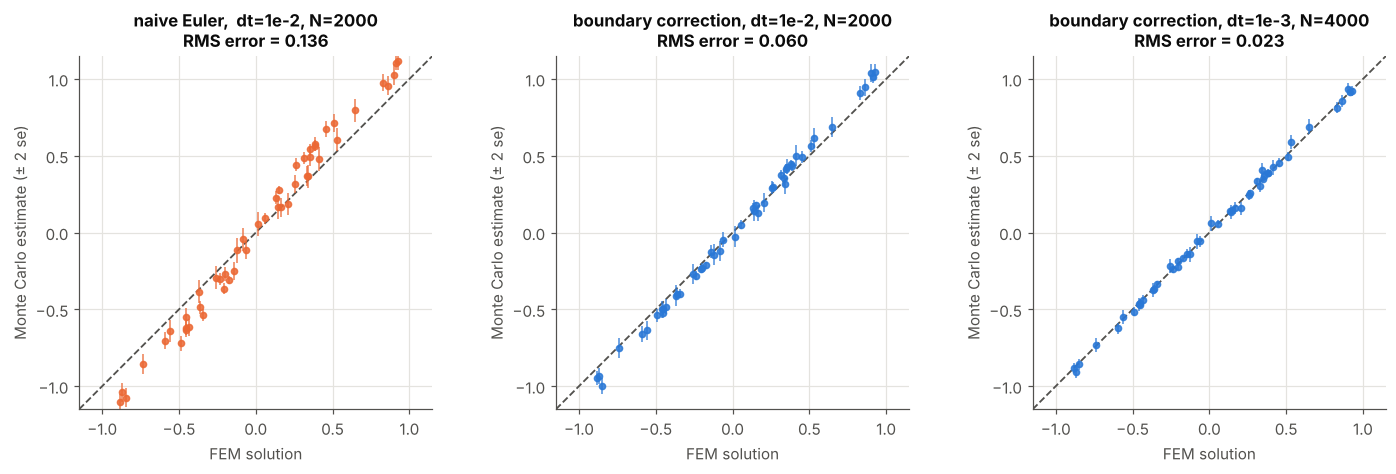

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), constrained_layout=True)
lim = (-1.15, 1.15)
for ax, (label, u_mc, se) in zip(axes, results):
    ax.plot(lim, lim, color=plotstyle.MUTED, lw=1.2, ls="--")
    color = plotstyle.ORANGE if "naive" in label else plotstyle.BLUE
    ax.errorbar(u_fem, u_mc, yerr=2 * se, fmt="o", ms=4, color=color, ecolor=color, elinewidth=1, alpha=0.85)
    rms = np.sqrt(np.mean((u_mc - u_fem) ** 2))
    ax.set(title=f"{label}\nRMS error = {rms:.3f}", xlabel="FEM solution", ylabel="Monte Carlo estimate (± 2 se)",
           xlim=lim, ylim=lim, aspect="equal")
fig.savefig("figures/fem_vs_mc_scatter.png")
plt.show()

**What we see.**

* The naive scheme is **not** noisy around the FEM values: its error bars are small, yet the points sit systematically off the diagonal, *away from zero*: it **overestimates $|u|$** (column `|MC|>|FEM|`: nearly all points, and all of those with $|u|>0.5$). Most points are more than three standard errors from the reference (column `|z|>3`). That is a *bias*, not noise.
* With the **same cost** the boundary correction more than halves the RMS error, but at $\Delta t=10^{-2}$ some bias remains. With $\Delta t=10^{-3}$ the points fall on the diagonal: no point is beyond three standard errors and the RMS error is about 1.4 times the mean standard error (a small residual bias is still there; Section 3 quantifies it).

*(The first version of this project reported an "$L^2$ error" of 0.26 for the naive scheme. That figure is $\sqrt{|D|\cdot\mathrm{mean}(\mathrm{diff}^2)}$ with $|D|=4$, i.e. twice the RMS error computed here. It is the same discrepancy.)*

**Why does the naive scheme overestimate?** It looks at the path only at the times $m\Delta t$. A path that crosses the boundary and comes back between two steps is not detected, so it keeps running: the simulated exit time $\tau$ is too large and the integral $\int_0^\tau g$ accumulates too much. With $\Delta t=10^{-2}$ and $\sigma=\sqrt2$, a single step moves a path by about $0.14$, a sizeable fraction of the distance to the boundary. This is not a failure of the theory; it is the discretisation of the *stopping rule*.

Two lessons:

1. The Monte Carlo standard error measures **only** the statistical error. It is blind to this bias, so one must always test against an independent reference.
2. We need an exact solution to separate the errors of the two methods. That is Section 3.

## 3. A problem with a known exact solution

Choose $u^\*(x,y)=\sin(\pi x)\sin(\pi y)$, which vanishes on $\partial D$, and **manufacture** the source term that makes it the solution of $\Delta u+b\cdot\nabla u=-g$:

$$
g=-\Delta u^\*-b\cdot\nabla u^\*=2\pi^2u^\*-\pi\big(b_1\cos(\pi x)\sin(\pi y)+b_2\sin(\pi x)\cos(\pi y)\big).
$$

Same domain, same drift, same operator: only $g$ changes. Now both methods can be compared with the truth.

**Finite elements.** For $P_1$ elements we expect $\|u-u_h\|=O(h^2)$.

In [5]:
u_exact = lambda X: np.sin(np.pi * X[:, 0]) * np.sin(np.pi * X[:, 1])

def g_manufactured(X):
    x, y = X[:, 0], X[:, 1]
    return (2 * np.pi**2 * np.sin(np.pi * x) * np.sin(np.pi * y)
            - np.pi * (b[0] * np.cos(np.pi * x) * np.sin(np.pi * y) + b[1] * np.sin(np.pi * x) * np.cos(np.pi * y)))

# error of the P1 FEM on a fine evaluation grid inside D
gx = np.linspace(-0.85, 0.85, 41)
G = np.array([(x, y) for x in gx for y in gx])
ns = np.array([10, 20, 40, 80, 160])
fem_err = []
for n in ns:
    s = solve_dirichlet_poisson(a, b, g_manufactured, phi, [-1, -1], [1, 1], nx=n)
    fem_err.append(np.abs(s(G) - u_exact(G)).max())
fem_err = np.array(fem_err)
h = 2.0 / ns
slope_fem = np.polyfit(np.log(h), np.log(fem_err), 1)[0]
for n, e in zip(ns, fem_err):
    print(f"n = {n:>3} (h = {2 / n:.4f})   max error = {e:.2e}")
print(f"\nobserved order of convergence of FEM: {slope_fem:.2f}   (theory: 2)")

n =  10 (h = 0.2000)   max error = 1.27e-01
n =  20 (h = 0.1000)   max error = 3.26e-02
n =  40 (h = 0.0500)   max error = 8.24e-03
n =  80 (h = 0.0250)   max error = 2.03e-03
n = 160 (h = 0.0125)   max error = 5.17e-04

observed order of convergence of FEM: 1.99   (theory: 2)

**Monte Carlo.** Now the time-step study. For each $\Delta t$ we estimate $u$ at the 49 points with $N=20{,}000$ paths per point, with and without the boundary correction, and measure the RMS error with respect to the exact solution.

The total error mixes noise and bias. Since the noise level is known (it is the RMS of the standard errors, the *floor*), we isolate the bias as
$\ \text{bias}\approx\sqrt{\max(\text{RMS}^2-\text{floor}^2,\,0)}$.

*(This cell takes about a minute.)*

In [6]:
ex = u_exact(pts)
dts = np.array([2e-2, 1e-2, 5e-3, 2.5e-3, 1.25e-3])
N = 20000

def sweep(corr, seed):
    out = []
    for dt in dts:
        u_mc, se = feynman_kac_solver(a, b, g_manufactured, phi, pts, D, N=N, dt=dt,
                                      boundary_correction=corr, seed=seed, verbose=False)
        rms = np.sqrt(np.mean((u_mc - ex) ** 2))
        floor = np.sqrt(np.mean(se ** 2))
        out.append((rms, floor, np.sqrt(max(rms**2 - floor**2, 0.0))))
    return np.array(out)

naive, corrected = sweep(False, 10), sweep(True, 11)

print(f"{'dt':>9} | {'naive: RMS':>10} {'bias':>8} | {'corrected: RMS':>14} {'bias':>8} | {'noise floor':>11}")
for dt, n_, c_ in zip(dts, naive, corrected):
    print(f"{dt:>9.2e} | {n_[0]:>10.4f} {n_[2]:>8.4f} | {c_[0]:>14.4f} {c_[2]:>8.4f} | {c_[1]:>11.4f}")

# observed order on the first three time steps (where the bias dominates the noise)
k = 3
slope_naive = np.polyfit(np.log(dts[:k]), np.log(naive[:k, 2]), 1)[0]
slope_corr  = np.polyfit(np.log(dts[:k]), np.log(corrected[:k, 2]), 1)[0]
print(f"\nobserved order in dt (bias, first {k} steps):  naive = {slope_naive:.2f}   corrected = {slope_corr:.2f}")
print("theory:                                       naive = 0.50   corrected = 1.00")

       dt | naive: RMS     bias | corrected: RMS     bias | noise floor
 2.00e-02 |     0.2235   0.2232 |         0.1193   0.1190 |      0.0082
 1.00e-02 |     0.1405   0.1402 |         0.0566   0.0560 |      0.0081
 5.00e-03 |     0.0930   0.0925 |         0.0272   0.0260 |      0.0081
 2.50e-03 |     0.0632   0.0626 |         0.0144   0.0119 |      0.0080
 1.25e-03 |     0.0450   0.0442 |         0.0094   0.0048 |      0.0080

observed order in dt (bias, first 3 steps):  naive = 0.64   corrected = 1.10
theory:                                       naive = 0.50   corrected = 1.00

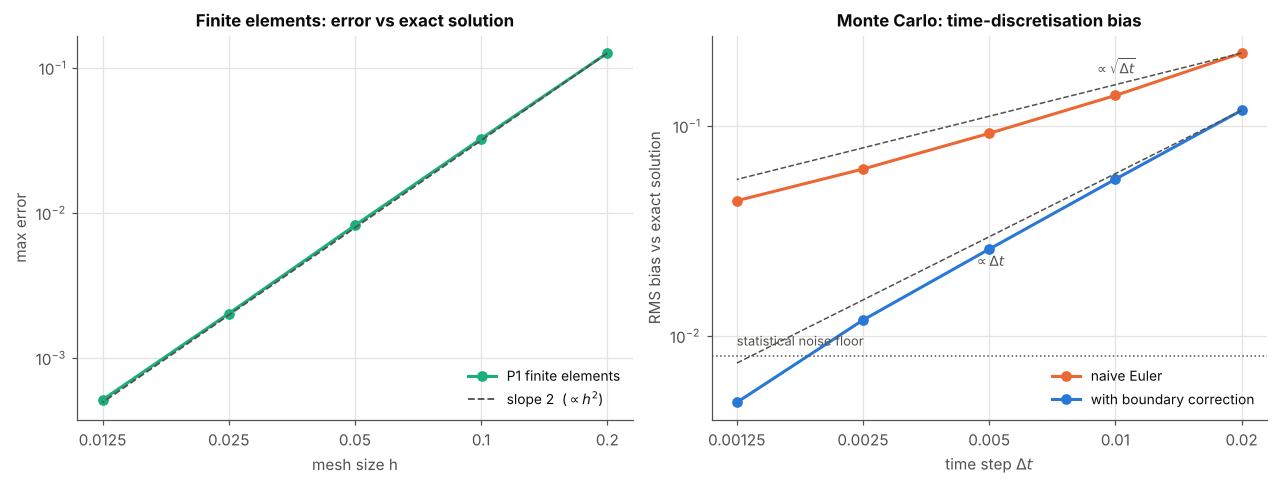

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), constrained_layout=True)

# --- FEM ---
ax = axes[0]
ax.loglog(h, fem_err, "o-", color=plotstyle.AQUA, label="P1 finite elements")
ax.loglog(h, fem_err[0] * (h / h[0]) ** 2, ls="--", color=plotstyle.MUTED, lw=1.2, label=r"slope 2  ($\propto h^2$)")
ax.set(title="Finite elements: error vs exact solution", xlabel="mesh size h", ylabel="max error")
ax.set_xticks(h); ax.set_xticklabels([f"{v:.3g}" for v in h]); ax.minorticks_off()
ax.legend(loc="lower right")

# --- Monte Carlo ---
ax = axes[1]
ax.loglog(dts, naive[:, 2], "o-", color=plotstyle.ORANGE, label="naive Euler")
ax.loglog(dts, corrected[:, 2], "o-", color=plotstyle.BLUE, label="with boundary correction")
ax.loglog(dts, naive[0, 2] * (dts / dts[0]) ** 0.5, ls="--", color=plotstyle.MUTED, lw=1.0)
ax.loglog(dts, corrected[0, 2] * (dts / dts[0]) ** 1.0, ls="--", color=plotstyle.MUTED, lw=1.0)
ax.axhline(corrected[:, 1].mean(), color=plotstyle.MUTED, lw=1.0, ls=":")
ax.text(dts[-1], corrected[:, 1].mean() * 1.08, "statistical noise floor", ha="left", va="bottom", color=plotstyle.MUTED, fontsize=8.5)
ax.text(dts[1], naive[0, 2] * (dts[1] / dts[0]) ** 0.5 * 1.12, r"$\propto\sqrt{\Delta t}$", ha="center", color=plotstyle.MUTED, fontsize=9)
ax.text(dts[2], corrected[0, 2] * (dts[2] / dts[0]) * 0.72, r"$\propto\Delta t$", ha="center", color=plotstyle.MUTED, fontsize=9)
ax.set_xticks(dts); ax.set_xticklabels([f"{v:.3g}" for v in dts]); ax.minorticks_off()
ax.set(title="Monte Carlo: time-discretisation bias", xlabel=r"time step $\Delta t$", ylabel="RMS bias vs exact solution")
ax.legend(loc="lower right")
fig.savefig("figures/convergence.png")
plt.show()

**Reading the plots.**

* **FEM** converges with order $\approx2$, as theory predicts. At $n=60$ its error is of order $10^{-3}$, far below the Monte Carlo errors in Section 2, so using it as the reference there was legitimate.
* **Naive Monte Carlo** has a bias that decays slowly in $\Delta t$ (observed order about $0.6$, close to the asymptotic $1/2$). Halving the bias costs several times more steps.
* **Boundary correction** is much smaller at every $\Delta t$ and decays faster (observed order about $1.1$, close to the theoretical $1$) until it approaches the statistical noise floor; below that level only more paths ($N$) help.

The correction costs nothing: it is one line, a shifted stopping test.

In [8]:
# Cost of reaching a given accuracy at the 49 points (problem of Section 3)
t0 = time.perf_counter()
s80 = solve_dirichlet_poisson(a, b, g_manufactured, phi, [-1, -1], [1, 1], nx=80)
t_fem = time.perf_counter() - t0
err_fem = np.abs(s80(pts) - ex).max()

t0 = time.perf_counter()
u_mc, se = feynman_kac_solver(a, b, g_manufactured, phi, pts, D, N=20000, dt=2.5e-3, seed=3, verbose=False)
t_mc = time.perf_counter() - t0

print(f"FEM (80x80, whole domain):        max error {err_fem:.1e}   time {t_fem:.2f} s")
print(f"Monte Carlo (49 points only):     max error {np.abs(u_mc - ex).max():.1e}   time {t_mc:.2f} s")

FEM (80x80, whole domain):        max error 1.8e-03   time 0.05 s
Monte Carlo (49 points only):     max error 4.1e-02   time 7.37 s

## 4. Conclusions

1. **The theory works.** Once the discretisation is handled properly, the average over diffusion paths reproduces the PDE solution within its statistical error, and agrees with an independent finite-element solution.
2. **The first discrepancy was a bias of the simulation, not of the theory.** It came from monitoring the exit only at discrete times, an $O(\sqrt{\Delta t})$ effect. The boundary shift reduces it to $O(\Delta t)$ at no extra cost.
3. **The standard error cannot detect the bias.** Always validate against an independent reference (FEM, or a manufactured exact solution).
4. **In 2-D on a square, FEM is the better tool**: it is more accurate and gives the whole field in a fraction of a second. Monte Carlo pays off when the problem is high-dimensional, when the geometry is awkward to mesh, or when only a few values are needed. That is the subject of the next notebook, with a real application.

➡️ Next: [3. A real-world application](03_application.ipynb)